In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# display settings
pd.set_option('display.max_columns', None)

In [2]:
# load the admissions dataset
df = pd.read_csv('Admission_Prediction_TimeSeries_Ready.csv')

# display dataset dimensions and column names
print('dataset shape:', df.shape)
print('columns in dataset:', df.columns.tolist())

# show first five rows
df.head()

dataset shape: (1000, 12)
columns in dataset: ['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Application_DateTime', 'University_Name', 'region']


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# convert application datetime to datetime format
df['Application_DateTime'] = pd.to_datetime(df['Application_DateTime'])

# sort records chronologically
df = df.sort_values('Application_DateTime').reset_index(drop=True)

# define admitted applicant using threshold of 70 percent chance
df['admitted'] = (df['Chance of Admit'] >= 0.70).astype(int)

# extract calendar date features
df['year'] = df['Application_DateTime'].dt.year
df['month'] = df['Application_DateTime'].dt.month
df['month_name'] = df['Application_DateTime'].dt.month_name()

# display sample preprocessed records
df[['Application_DateTime', 'GRE Score', 'TOEFL Score', 'Chance of Admit', 'admitted']].head()

,Application_DateTime,GRE Score,TOEFL Score,Chance of Admit,admitted
0,2022-01-01 09:00:00,337,118,0.92,1
1,2022-01-02 09:00:00,324,107,0.76,1
2,2022-01-04 09:00:00,316,104,0.72,1
3,2022-01-06 09:00:00,322,110,0.80,1
4,2022-01-08 09:00:00,314,103,0.65,0


In [4]:
# set application datetime as index for time series analysis
ts_df = df.set_index('Application_DateTime')

# aggregate data at monthly frequency
monthly = ts_df.resample('ME').agg({
    'Serial No.': 'count',
    'admitted': 'sum',
    'Chance of Admit': 'mean',
    'GRE Score': 'mean'
}).rename(columns={'Serial No.': 'applicants'})

# calculate enrolled students using standard 80 percent enrollment yield rate
monthly['enrolled'] = (monthly['admitted'] * 0.80).round().astype(int)

# display monthly aggregated summary
print('monthly time series shape:', monthly.shape)
monthly.head(10)

monthly time series shape: (60, 5)


,applicants,admitted,Chance of Admit,GRE Score,enrolled
Application_DateTime,,,,,
2022-01-31,17,8,0.688235,319.176471,6
2022-02-28,16,8,0.721250,319.062500,6
2022-03-31,17,10,0.731176,319.647059,8
2022-04-30,16,4,0.572500,314.687500,3
2022-05-31,17,10,0.731176,319.117647,8
2022-06-30,16,7,0.637500,314.687500,6
2022-07-31,17,7,0.708235,317.647059,6
2022-08-31,17,10,0.722941,314.823529,8
2022-09-30,17,17,0.830588,324.117647,14


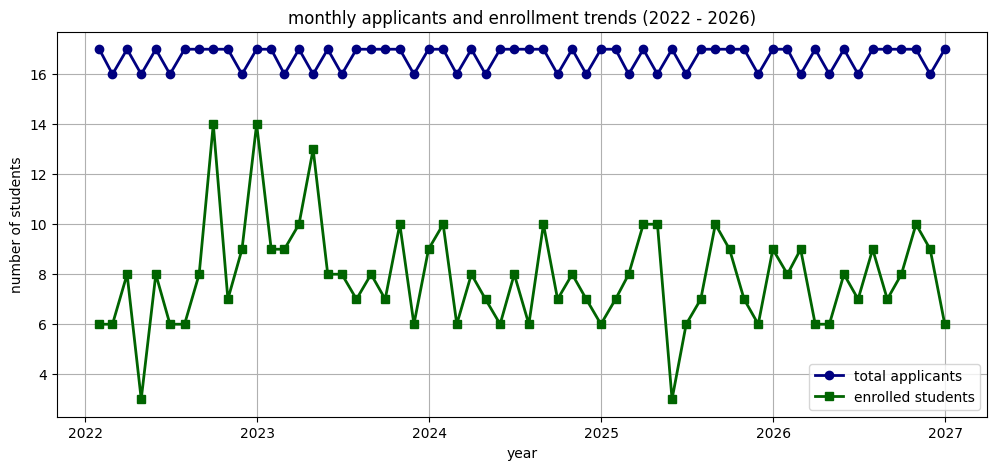

In [5]:
# plot monthly applicants and enrolled students over time
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly['applicants'], label='total applicants', color='navy', marker='o', linewidth=2)
plt.plot(monthly.index, monthly['enrolled'], label='enrolled students', color='darkgreen', marker='s', linewidth=2)
plt.title('monthly applicants and enrollment trends (2022 - 2026)')
plt.xlabel('year')
plt.ylabel('number of students')
plt.legend()
plt.grid(True)
plt.show()

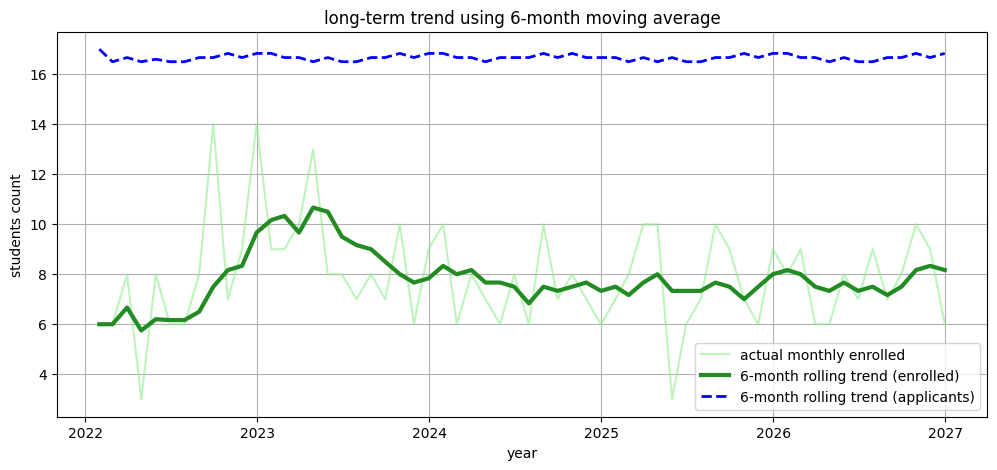

In [6]:
# calculate 6-month rolling moving average for long-term trend
monthly['enrolled_6m_ma'] = monthly['enrolled'].rolling(window=6, min_periods=1).mean()
monthly['applicants_6m_ma'] = monthly['applicants'].rolling(window=6, min_periods=1).mean()

# plot moving averages to reveal smooth long-term trend
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly['enrolled'], label='actual monthly enrolled', color='lightgreen', alpha=0.6)
plt.plot(monthly.index, monthly['enrolled_6m_ma'], label='6-month rolling trend (enrolled)', color='forestgreen', linewidth=3)
plt.plot(monthly.index, monthly['applicants_6m_ma'], label='6-month rolling trend (applicants)', color='blue', linewidth=2, linestyle='--')
plt.title('long-term trend using 6-month moving average')
plt.xlabel('year')
plt.ylabel('students count')
plt.legend()
plt.grid(True)
plt.show()

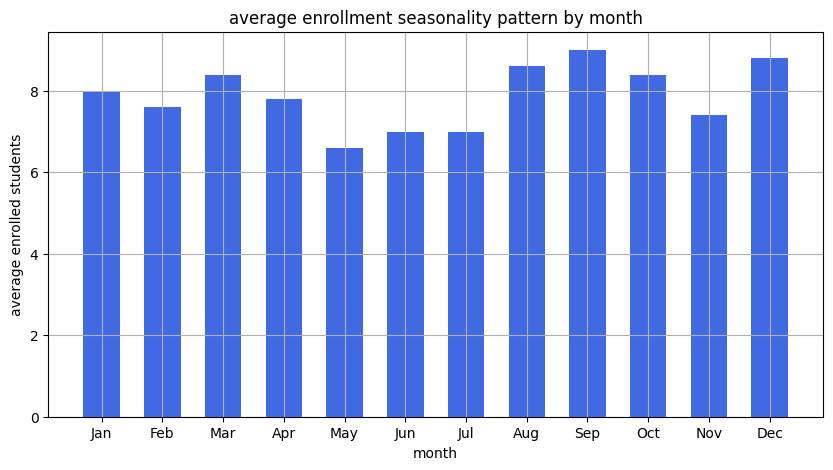

In [7]:
# calculate average monthly seasonality across all years
monthly_seasonality = monthly.groupby(monthly.index.month).agg({
    'applicants': 'mean',
    'admitted': 'mean',
    'enrolled': 'mean'
}).reset_index()

# list month names for readability
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_seasonality['month_label'] = month_labels

# plot monthly seasonality profile
plt.figure(figsize=(10, 5))
plt.bar(monthly_seasonality['month_label'], monthly_seasonality['enrolled'], color='royalblue', width=0.6)
plt.title('average enrollment seasonality pattern by month')
plt.xlabel('month')
plt.ylabel('average enrolled students')
plt.grid(True)
plt.show()

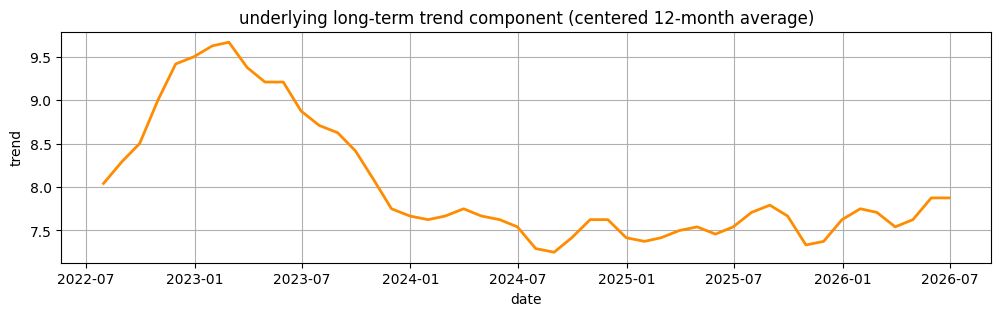

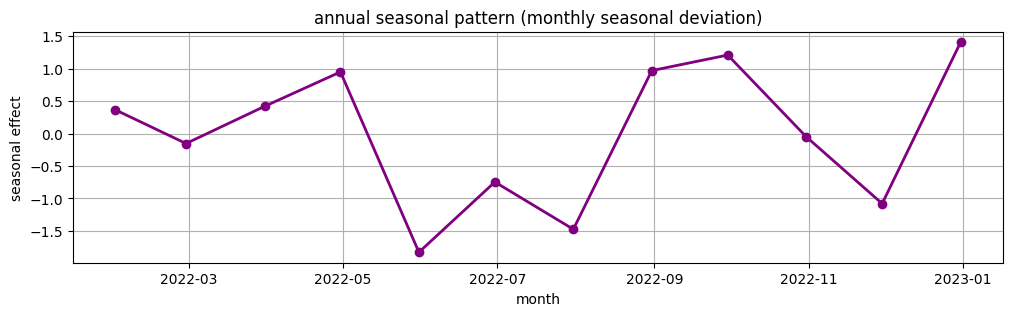

In [8]:
# perform classical additive seasonal decomposition
decomp = seasonal_decompose(monthly['enrolled'], model='additive', period=12)

# plot trend component without axis objects
plt.figure(figsize=(12, 3))
plt.plot(decomp.trend.index, decomp.trend, color='darkorange', linewidth=2)
plt.title('underlying long-term trend component (centered 12-month average)')
plt.xlabel('date')
plt.ylabel('trend')
plt.grid(True)
plt.show()

# plot seasonal component without axis objects
plt.figure(figsize=(12, 3))
plt.plot(decomp.seasonal.index[:12], decomp.seasonal.values[:12], color='purple', marker='o', linewidth=2)
plt.title('annual seasonal pattern (monthly seasonal deviation)')
plt.xlabel('month')
plt.ylabel('seasonal effect')
plt.grid(True)
plt.show()

In [9]:
# fit exponential smoothing model for applicant volume
model_app = ExponentialSmoothing(monthly['applicants'], trend='add', seasonal='add', seasonal_periods=12).fit()
forecast_app = model_app.forecast(12)

# fit exponential smoothing model for enrolled volume
model_enr = ExponentialSmoothing(monthly['enrolled'].astype(float), trend='add', seasonal='add', seasonal_periods=12).fit()
forecast_enr = model_enr.forecast(12)

# create forecast summary dataframe
forecast_dates = pd.date_range(start='2027-01-01', periods=12, freq='ME')
forecast_df = pd.DataFrame({
    'date': forecast_dates.strftime('%Y-%m'),
    'month': month_labels,
    'forecast_applicants': forecast_app.values.round().astype(int),
    'forecast_enrolled': forecast_enr.values.round().astype(int)
})

# display forecasted values for 2027
forecast_df

,date,month,forecast_applicants,forecast_enrolled
0,2027-01,Jan,17,8
1,2027-02,Feb,16,7
2,2027-03,Mar,17,8
3,2027-04,Apr,16,7
4,2027-05,May,17,6
5,2027-06,Jun,16,7
6,2027-07,Jul,17,7
7,2027-08,Aug,17,8
8,2027-09,Sep,17,9
9,2027-10,Oct,17,8


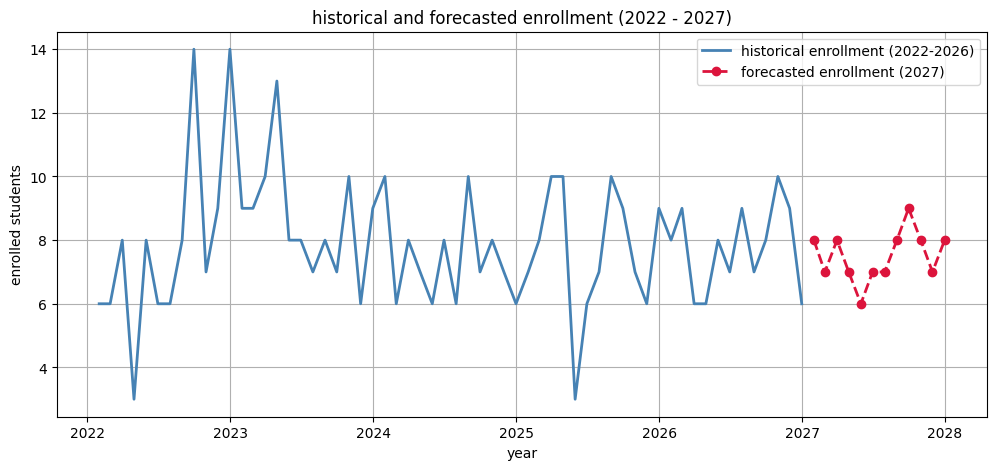

In [10]:
# plot historical and forecasted enrollment
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly['enrolled'], label='historical enrollment (2022-2026)', color='steelblue', linewidth=2)
plt.plot(forecast_dates, forecast_df['forecast_enrolled'], label='forecasted enrollment (2027)', color='crimson', marker='o', linestyle='--', linewidth=2)
plt.title('historical and forecasted enrollment (2022 - 2027)')
plt.xlabel('year')
plt.ylabel('enrolled students')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# calculate total forecasted applicants and enrolled students for 2027
total_forecast_applicants = int(forecast_df['forecast_applicants'].sum())
total_forecast_enrolled = int(forecast_df['forecast_enrolled'].sum())
peak_monthly_enrolled = int(forecast_df['forecast_enrolled'].max())

print('total forecasted applicants (2027):', total_forecast_applicants)
print('total forecasted enrolled students (2027):', total_forecast_enrolled)
print('peak monthly enrollment cohort:', peak_monthly_enrolled)

total forecasted applicants (2027): 200
total forecasted enrolled students (2027): 90
peak monthly enrollment cohort: 9


In [12]:
# capacity planning parameter benchmarks
buffer_rate = 0.15 # 15 percent safety and scheduling buffer
student_faculty_ratio = 15 # 15 students per faculty member
hostel_demand_rate = 0.70 # 70 percent students require campus housing
lab_workstation_rate = 0.50 # 50 percent need concurrent computer lab access
applications_per_officer = 50 # 1 admissions officer can handle 50 applications

# compute required capacities
classroom_seats_needed = int(np.ceil(total_forecast_enrolled * (1 + buffer_rate)))
faculty_needed = int(np.ceil(total_forecast_enrolled / student_faculty_ratio))
hostel_beds_needed = int(np.ceil(total_forecast_enrolled * hostel_demand_rate))
lab_workstations_needed = int(np.ceil(total_forecast_enrolled * lab_workstation_rate))
admissions_officers_needed = int(np.ceil(total_forecast_applicants / applications_per_officer))

# build capacity summary dataframe
capacity_df = pd.DataFrame({
    'resource requirement': [
        'classroom seats (with 15% safety buffer)',
        'faculty members (15:1 student-faculty ratio)',
        'hostel beds (70% residential demand)',
        'computer lab workstations (50% concurrent access)',
        'admissions officers (1 per 50 applicants)'
    ],
    'forecasted demand': [
        classroom_seats_needed,
        faculty_needed,
        hostel_beds_needed,
        lab_workstations_needed,
        admissions_officers_needed
    ],
    'unit': ['seats', 'faculty staff', 'beds', 'workstations', 'officers']
})

# display capacity summary table
capacity_df

,resource requirement,forecasted demand,unit
0,classroom seats (with 15% safety buffer),104,seats
1,faculty members (15:1 student-faculty ratio),6,faculty staff
2,hostel beds (70% residential demand),63,beds
3,computer lab workstations (50% concurrent access),45,workstations
4,admissions officers (1 per 50 applicants),4,officers


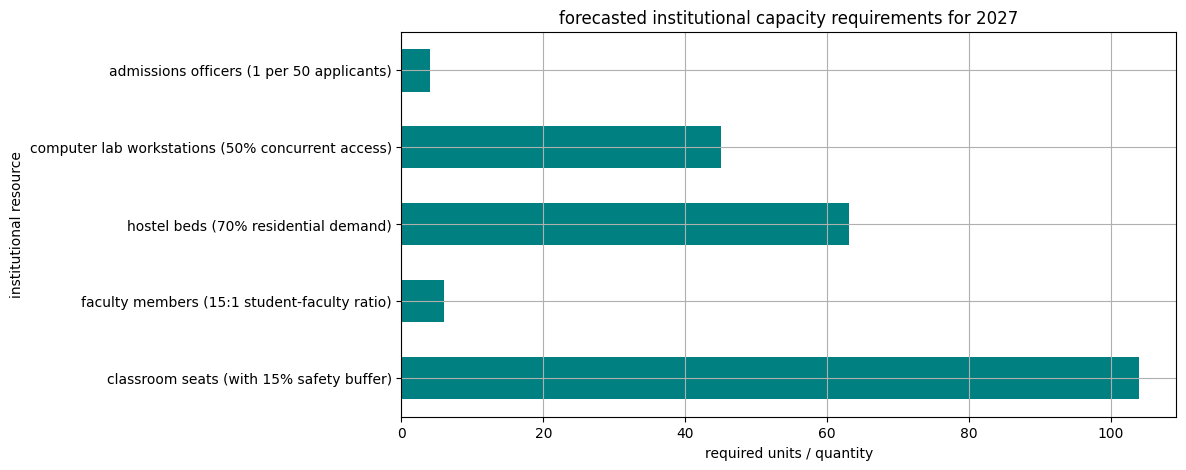

In [13]:
# plot capacity requirements using horizontal bar chart
plt.figure(figsize=(10, 5))
plt.barh(capacity_df['resource requirement'], capacity_df['forecasted demand'], color='teal', height=0.55)
plt.title('forecasted institutional capacity requirements for 2027')
plt.xlabel('required units / quantity')
plt.ylabel('institutional resource')
plt.grid(True)
plt.show()